In [6]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("zalando-research/fashionmnist")

print("Path to dataset files:", path)

Path to dataset files: C:\Users\shiva\.cache\kagglehub\datasets\zalando-research\fashionmnist\versions\4


In [76]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score,ConfusionMatrixDisplay
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import LinearSVC
%pip install tensorflow
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D
from tensorflow.keras.layers import Flatten, Dense, Dropout

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [8]:


df = pd.read_csv(path + "/fashion-mnist_train.csv")
df.head()


,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,6,0,0,0,0,0,0,0,5,0,...,0,0,0,30,43,0,0,0,0,0
3,0,0,0,0,1,2,0,0,0,0,...,3,0,0,0,0,1,0,0,0,0
4,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [9]:
dftest = pd.read_csv(path + "/fashion-mnist_test.csv")
dftest.head()

,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,0,0,0,0,0,0,0,0,9,8,...,103,87,56,0,0,0,0,0,0,0
1,1,0,0,0,0,0,0,0,0,0,...,34,0,0,0,0,0,0,0,0,0
2,2,0,0,0,0,0,0,14,53,99,...,0,0,0,0,63,53,31,0,0,0
3,2,0,0,0,0,0,0,0,0,0,...,137,126,140,0,133,224,222,56,0,0
4,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [10]:
print(df.shape)
print(df.info())
print(df.describe())

(60000, 785)
<class 'pandas.DataFrame'>
RangeIndex: 60000 entries, 0 to 59999
Columns: 785 entries, label to pixel784
dtypes: int64(785)
memory usage: 359.3 MB
None
              label        pixel1        pixel2        pixel3        pixel4  \
count  60000.000000  60000.000000  60000.000000  60000.000000  60000.000000   
mean       4.500000      0.000900      0.006150      0.035333      0.101933   
std        2.872305      0.094689      0.271011      1.222324      2.452871   
min        0.000000      0.000000      0.000000      0.000000      0.000000   
25%        2.000000      0.000000      0.000000      0.000000      0.000000   
50%        4.500000      0.000000      0.000000      0.000000      0.000000   
75%        7.000000      0.000000      0.000000      0.000000      0.000000   
max        9.000000     16.000000     36.000000    226.000000    164.000000   

             pixel5        pixel6        pixel7        pixel8        pixel9  \
count  60000.000000  60000.000000  60000.000

In [11]:
label = df["label"]
all_features = df.drop(["label"], axis=1)
print(label.shape)
print(all_features.shape)

(60000,)
(60000, 784)


In [12]:
labelTest = dftest['label']
all_featuresTest = dftest.drop(['label'], axis=1)
print(labelTest.shape)
print(all_featuresTest.shape)

(10000,)
(10000, 784)


In [13]:
all_features = np.array(all_features)
label = np.array(label)

In [14]:
all_featuresTest = np.array(all_featuresTest)
labelTest = np.array(labelTest)

In [15]:
all_features = all_features.reshape(-1,28,28)

In [16]:
all_featuresTest = all_featuresTest.reshape(-1,28,28)

In [17]:
class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

In [18]:
print(np.unique(label, return_counts=True))

(array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9]), array([6000, 6000, 6000, 6000, 6000, 6000, 6000, 6000, 6000, 6000]))


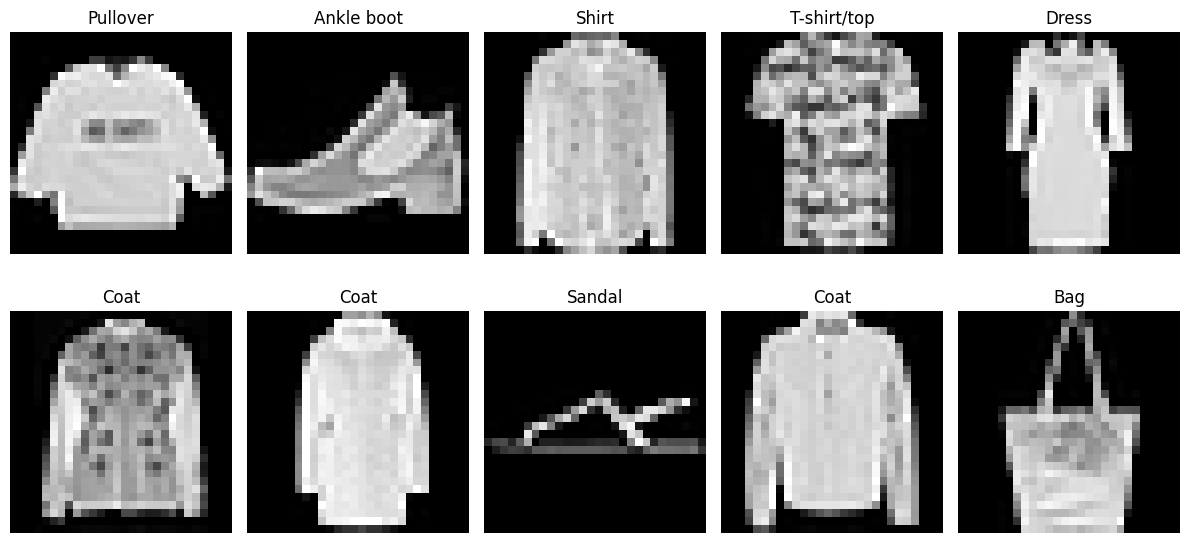

In [19]:

fig, axes = plt.subplots(2, 5, figsize=(12, 6))
axes = axes.flatten()

for i in range(10):
    axes[i].imshow(all_features[i], cmap='gray')
    axes[i].set_title(class_names[label[i]])
    axes[i].axis('off')

plt.tight_layout()
plt.show()

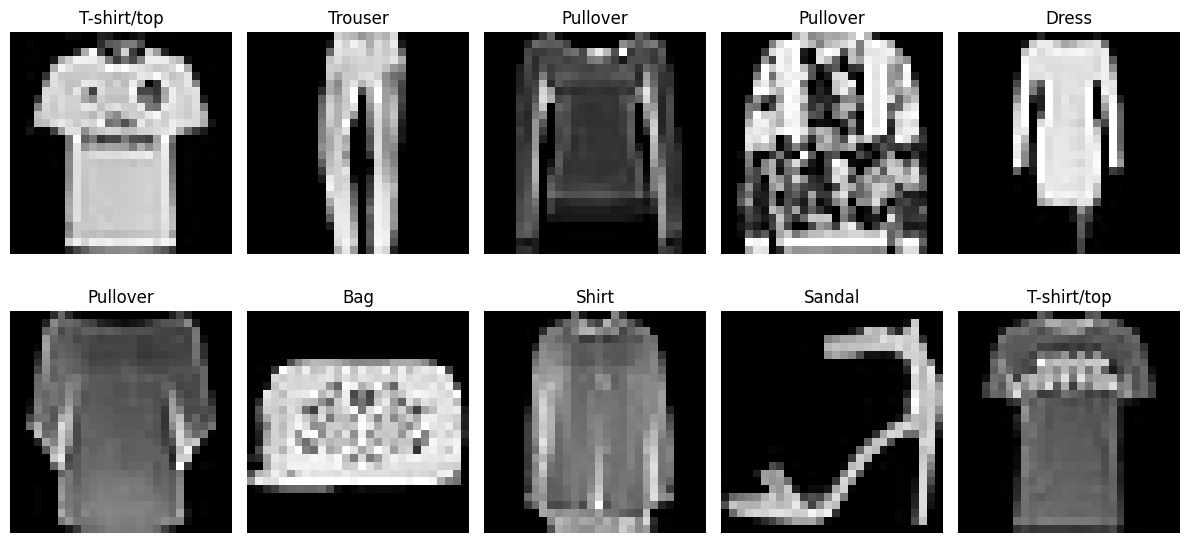

In [20]:

fig, axes = plt.subplots(2, 5, figsize=(12, 6))
axes = axes.flatten()

for i in range(10):
    axes[i].imshow(all_featuresTest[i], cmap='gray')
    axes[i].set_title(class_names[labelTest[i]])
    axes[i].axis('off')

plt.tight_layout()
plt.show()

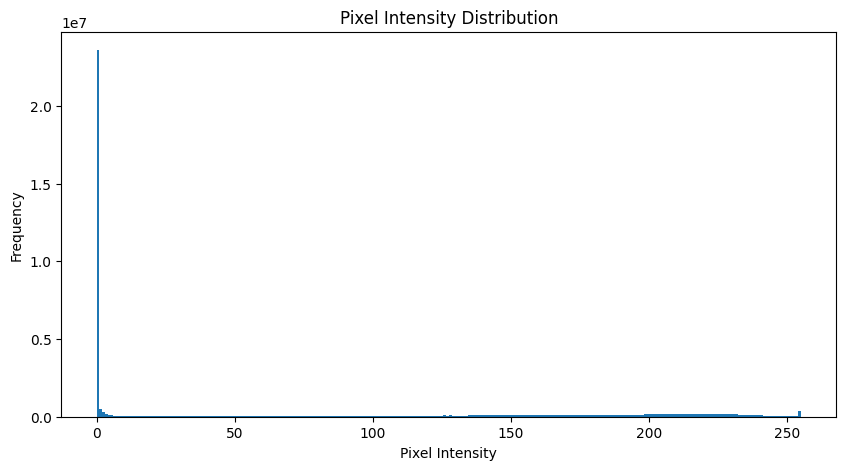

In [21]:
plt.figure(figsize=(10, 5))

plt.hist(
    all_features.flatten(),
    bins=256,
    range=(0, 255)
)

plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")
plt.title("Pixel Intensity Distribution")

plt.show()

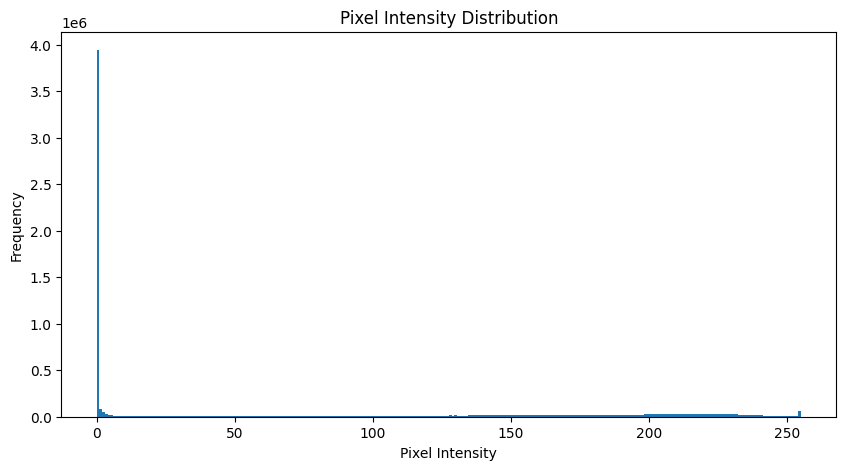

In [22]:
plt.figure(figsize=(10, 5))

plt.hist(
    all_featuresTest.flatten(),
    bins=256,
    range=(0, 255)
)

plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")
plt.title("Pixel Intensity Distribution")

plt.show()

In [23]:
normalised_feature = all_features / 255.0
normalised_featureTest = all_featuresTest / 255.0

In [24]:
print(normalised_feature[0])
print(normalised_featureTest[0])

[[0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.        ]
 [0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.        ]
 [0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.        ]
 [0.         0.         0.         0.         0.01568627 0.
  0.         0.         0.         0.         0.24313725 0.23921569
  0.0823529

In [25]:
print("Original range:", all_features.min(), all_features.max())

print("Normalized range:",
      normalised_feature.min(),
      normalised_feature.max())

print("Original shape:", all_features.shape)
print("Normalized shape:", normalised_feature.shape)

Original range: 0 255
Normalized range: 0.0 1.0
Original shape: (60000, 28, 28)
Normalized shape: (60000, 28, 28)


In [26]:
print("Original range:", all_featuresTest.min(), all_featuresTest.max())

print("Normalized range:",
      normalised_featureTest.min(),
      normalised_featureTest.max())

print("Original shape:", all_featuresTest.shape)
print("Normalized shape:", normalised_feature.shape)

Original range: 0 255
Normalized range: 0.0 1.0
Original shape: (10000, 28, 28)
Normalized shape: (60000, 28, 28)


In [27]:
train_images = normalised_feature.reshape(-1,28,28)
test_images = normalised_featureTest.reshape(-1,28,28)

In [28]:
print(train_images.shape)
print(test_images.shape)

(60000, 28, 28)
(10000, 28, 28)


In [29]:
X_train, x_val, Y_train, y_val = train_test_split(train_images,label,test_size = 0.1,random_state = 42,stratify=label)

In [30]:
print(X_train.shape, x_val.shape, Y_train.shape, y_val.shape)

(54000, 28, 28) (6000, 28, 28) (54000,) (6000,)


In [31]:
print("Training distribution:")
print(np.unique(Y_train, return_counts=True))

print("Validation distribution:")
print(np.unique(y_val, return_counts=True))

Training distribution:
(array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9]), array([5400, 5400, 5400, 5400, 5400, 5400, 5400, 5400, 5400, 5400]))
Validation distribution:
(array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9]), array([600, 600, 600, 600, 600, 600, 600, 600, 600, 600]))


In [32]:
X_train_flat = X_train.reshape(X_train.shape[0], -1)
x_val_flat = x_val.reshape(x_val.shape[0], -1)

In [33]:
print("Training data:", X_train_flat.shape)
print("Validation data:", x_val_flat.shape)
print("Training labels:", Y_train.shape)
print("Validation labels:", y_val.shape)

Training data: (54000, 784)
Validation data: (6000, 784)
Training labels: (54000,)
Validation labels: (6000,)


In [34]:
model = LogisticRegression(
    max_iter=1000,
    tol=1e-3,
    solver='lbfgs'
)

model.fit(X_train_flat, Y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`mult

In [35]:
y_pred = model.predict(x_val_flat)
y_train_pred = model.predict(X_train_flat)

In [36]:
print(y_pred[:10])
print(y_val[:10])

[3 1 7 8 2 1 2 9 3 4]
[3 1 9 8 2 1 2 9 3 4]


In [37]:
accuracy = accuracy_score(y_val, y_pred)
accuracy_train = accuracy_score(Y_train, y_train_pred)

print("Training Accuracy:", accuracy_train)
print("Training Accuracy (%):", accuracy_train * 100)

print("Validation Accuracy:", accuracy)
print("Validation Accuracy (%):", accuracy * 100)

Training Accuracy: 0.8658703703703704
Training Accuracy (%): 86.58703703703704
Validation Accuracy: 0.8553333333333333
Validation Accuracy (%): 85.53333333333333


In [38]:
cm = confusion_matrix(y_val, y_pred)

print(cm)

[[497   4  12  26   5   1  48   0   7   0]
 [  2 585   2   8   1   0   2   0   0   0]
 [ 12   0 456   7  72   0  49   0   4   0]
 [ 18   9   5 529  21   0  16   0   2   0]
 [  2   1  42  24 483   0  46   0   2   0]
 [  1   0   0   0   0 549   0  33   4  13]
 [ 92   2  61  22  56   0 357   0  10   0]
 [  0   0   0   0   0  22   0 552   3  23]
 [  5   1   3   5   5   2  10   7 562   0]
 [  0   0   0   0   0   9   0  27   2 562]]


In [39]:
class_accuracy = cm.diagonal() / cm.sum(axis=1)

for i in range(10):
    print(
        class_names[i],
        round(class_accuracy[i] * 100, 2),
        "%"
    )

T-shirt/top 82.83 %
Trouser 97.5 %
Pullover 76.0 %
Dress 88.17 %
Coat 80.5 %
Sandal 91.5 %
Shirt 59.5 %
Sneaker 92.0 %
Bag 93.67 %
Ankle boot 93.67 %


In [40]:
print(classification_report(y_val, y_pred, target_names=class_names))

              precision    recall  f1-score   support

 T-shirt/top       0.79      0.83      0.81       600
     Trouser       0.97      0.97      0.97       600
    Pullover       0.78      0.76      0.77       600
       Dress       0.85      0.88      0.87       600
        Coat       0.75      0.81      0.78       600
      Sandal       0.94      0.92      0.93       600
       Shirt       0.68      0.59      0.63       600
     Sneaker       0.89      0.92      0.91       600
         Bag       0.94      0.94      0.94       600
  Ankle boot       0.94      0.94      0.94       600

    accuracy                           0.86      6000
   macro avg       0.85      0.86      0.85      6000
weighted avg       0.85      0.86      0.85      6000



In [41]:
misclassified_indices = np.where(y_pred != y_val)[0]
misclassified_indices_train = np.where(y_train_pred != Y_train)[0]
print("Total misclassified images:", len(misclassified_indices))
print("Total misclassified images of Trainning:", len(misclassified_indices_train))
print("First 10 misclassified indices:", misclassified_indices[:10])

Total misclassified images: 868
Total misclassified images of Trainning: 7243
First 10 misclassified indices: [ 2 13 17 21 28 29 30 37 51 63]


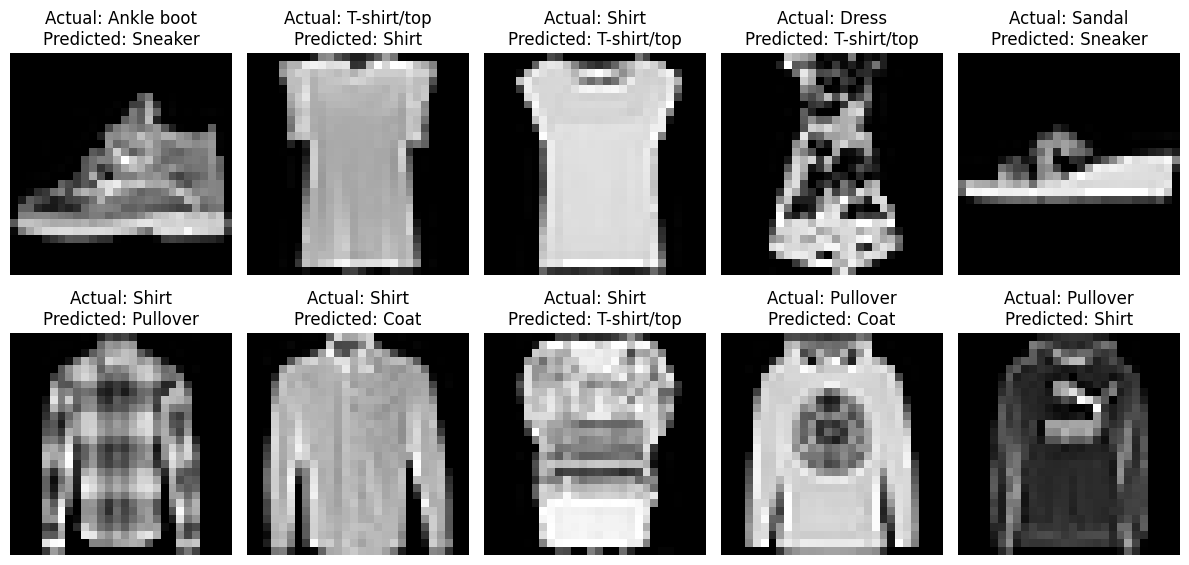

In [42]:
plt.figure(figsize=(12, 6))

for i in range(10):
    idx = misclassified_indices[i]

    plt.subplot(2, 5, i + 1)

    plt.imshow(x_val[idx], cmap='gray')

    actual = class_names[y_val[idx]]
    predicted = class_names[y_pred[idx]]

    plt.title(f"Actual: {actual}\nPredicted: {predicted}")
    plt.axis('off')

plt.tight_layout()
plt.show()

In [43]:
# Actual Shirt (6), predicted T-shirt/top (0)
shirt_as_tshirt = np.where(
    (y_val == 6) & (y_pred == 0)
)[0]

print("Number of Shirts predicted as T-shirts:", len(shirt_as_tshirt))

Number of Shirts predicted as T-shirts: 92


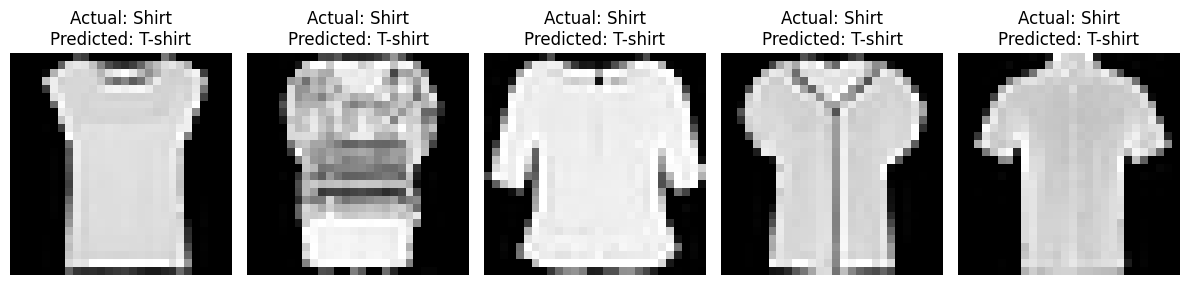

In [44]:
plt.figure(figsize=(12, 5))

for i in range(5):
    idx = shirt_as_tshirt[i]

    plt.subplot(1, 5, i + 1)
    plt.imshow(x_val[idx], cmap='gray')

    plt.title(
        f"Actual: Shirt\nPredicted: T-shirt"
    )
    plt.axis('off')

plt.tight_layout()
plt.show()

In [45]:
tshirt_as_shirt = np.where(
    (y_val == 0) & (y_pred == 6)
)[0]

print("Count:", len(tshirt_as_shirt))

Count: 48


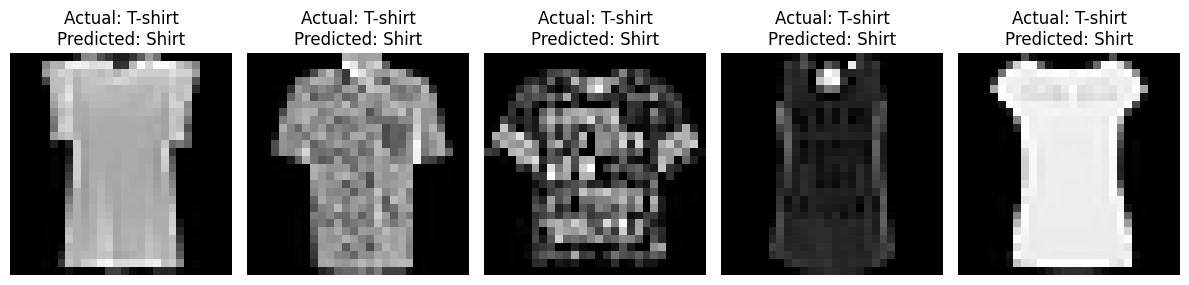

In [46]:
plt.figure(figsize=(12, 5))

for i in range(5):
    idx = tshirt_as_shirt[i]

    plt.subplot(1, 5, i + 1)
    plt.imshow(x_val[idx], cmap='gray')

    plt.title("Actual: T-shirt\nPredicted: Shirt")
    plt.axis('off')

plt.tight_layout()
plt.show()

In [47]:
for i in range(5):
    idx = tshirt_as_shirt[i]

    probabilities = model.predict_proba(
        x_val_flat[idx].reshape(1, -1)
    )[0]

    top_3 = np.argsort(probabilities)[-3:][::-1]

    print("\nActual:", class_names[y_val[idx]])

    for class_idx in top_3:
        print(
            class_names[class_idx],
            round(probabilities[class_idx] * 100, 2),
            "%"
        )


Actual: T-shirt/top
Shirt 55.39 %
T-shirt/top 39.38 %
Dress 4.76 %

Actual: T-shirt/top
Shirt 51.28 %
T-shirt/top 41.95 %
Coat 3.58 %

Actual: T-shirt/top
Shirt 73.39 %
Pullover 8.79 %
Bag 7.98 %

Actual: T-shirt/top
Shirt 43.1 %
T-shirt/top 25.6 %
Pullover 14.29 %

Actual: T-shirt/top
Shirt 67.8 %
T-shirt/top 30.8 %
Dress 1.12 %


In [48]:
nb_model = GaussianNB()

nb_model.fit(X_train_flat, Y_train)

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09


In [49]:
y_pred = nb_model.predict(x_val_flat)
y_train_pred = nb_model.predict(X_train_flat)

In [50]:
print("Training Accuracy:",
      accuracy_score(Y_train, y_train_pred) * 100)

print("Validation Accuracy:",
      accuracy_score(y_val, y_pred) * 100)

Training Accuracy: 58.1462962962963
Validation Accuracy: 58.03333333333334


In [51]:
svm_model = LinearSVC(
    C=0.01,
    max_iter=2000,
    random_state=42
)

In [52]:
svm_model.fit(X_train_flat,Y_train)
y_pred_val = svm_model.predict(x_val_flat)
y_pred_train = svm_model.predict(X_train_flat)

In [53]:
print("Training Accuracy:",
      accuracy_score(Y_train, y_pred_train) * 100)

print("Validation Accuracy:",
      accuracy_score(y_val, y_pred_val) * 100)

Training Accuracy: 86.42777777777778
Validation Accuracy: 84.83333333333334


Trying the Random Forest because it has the maximum accuracy in this

In [54]:
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=20,
    min_samples_leaf=2,
    min_samples_split=5,
    random_state=42,
    n_jobs=-1
)
rf_model.fit(X_train_flat, Y_train)

train_pred = rf_model.predict(X_train_flat)
val_pred = rf_model.predict(x_val_flat)

In [55]:
x_val_flat.shape

(6000, 784)

In [56]:
accuracy_train = accuracy_score(Y_train, train_pred)
accuracy = accuracy_score(y_val, val_pred)
print("Training Accuracy:", accuracy_train)
print("Training Accuracy (%):", accuracy_train * 100)

print("Validation Accuracy:", accuracy)
print("Validation Accuracy (%):", accuracy * 100)

Training Accuracy: 0.9879444444444444
Training Accuracy (%): 98.79444444444444
Validation Accuracy: 0.8786666666666667
Validation Accuracy (%): 87.86666666666667


In [57]:
print("Training data:", X_train_flat.shape)
print("Validation data:", x_val_flat.shape)
print("Training labels:", Y_train.shape)
print("Validation labels:", y_val.shape)

Training data: (54000, 784)
Validation data: (6000, 784)
Training labels: (54000,)
Validation labels: (6000,)


In [58]:
misclassified_indices_validation = np.where(val_pred != y_val)[0]
misclassified_indices_Training = np.where(train_pred != Y_train)[0]
print("Total misclassified images validation:", len(misclassified_indices_validation))
print("Total misclassified images training:", len(misclassified_indices_Training))
print("First 10 misclassified indices:", misclassified_indices_validation[:10])

Total misclassified images validation: 728
Total misclassified images training: 651
First 10 misclassified indices: [ 34  37  41  46  94  95  97 101 104 105]


In [59]:
cm = confusion_matrix(y_val, val_pred)

print(cm)

[[514   0   7  23   5   1  48   0   2   0]
 [  1 580   4  11   0   0   3   0   1   0]
 [  3   0 481   8  75   0  31   0   2   0]
 [ 10   4   5 550  21   0   9   0   1   0]
 [  4   1  49  24 499   0  22   0   1   0]
 [  0   0   0   0   0 579   1  14   2   4]
 [101   1  65  15  54   0 354   0  10   0]
 [  0   0   0   0   0   6   0 566   1  27]
 [  1   1   2   1   5   1   5   2 581   1]
 [  0   0   0   1   0   7   0  23   1 568]]


In [60]:
class_accuracy = cm.diagonal() / cm.sum(axis=1)

for i in range(10):
    print(
        class_names[i],
        round(class_accuracy[i] * 100, 2),
        "%"
    )

T-shirt/top 85.67 %
Trouser 96.67 %
Pullover 80.17 %
Dress 91.67 %
Coat 83.17 %
Sandal 96.5 %
Shirt 59.0 %
Sneaker 94.33 %
Bag 96.83 %
Ankle boot 94.67 %


In [61]:
print(classification_report(y_val, y_pred, target_names=class_names))

              precision    recall  f1-score   support

 T-shirt/top       0.80      0.62      0.70       600
     Trouser       0.62      0.95      0.75       600
    Pullover       0.60      0.29      0.39       600
       Dress       0.43      0.54      0.48       600
        Coat       0.36      0.75      0.49       600
      Sandal       0.89      0.28      0.42       600
       Shirt       0.25      0.02      0.04       600
     Sneaker       0.50      0.98      0.66       600
         Bag       0.84      0.71      0.77       600
  Ankle boot       0.94      0.67      0.78       600

    accuracy                           0.58      6000
   macro avg       0.62      0.58      0.55      6000
weighted avg       0.62      0.58      0.55      6000



In [62]:
shirt_index = class_names.index("Shirt")

print("Actual Shirt predictions:")

for i, class_name in enumerate(class_names):
    print(class_name, ":", cm[shirt_index][i])

Actual Shirt predictions:
T-shirt/top : 101
Trouser : 1
Pullover : 65
Dress : 15
Coat : 54
Sandal : 0
Shirt : 354
Sneaker : 0
Bag : 10
Ankle boot : 0


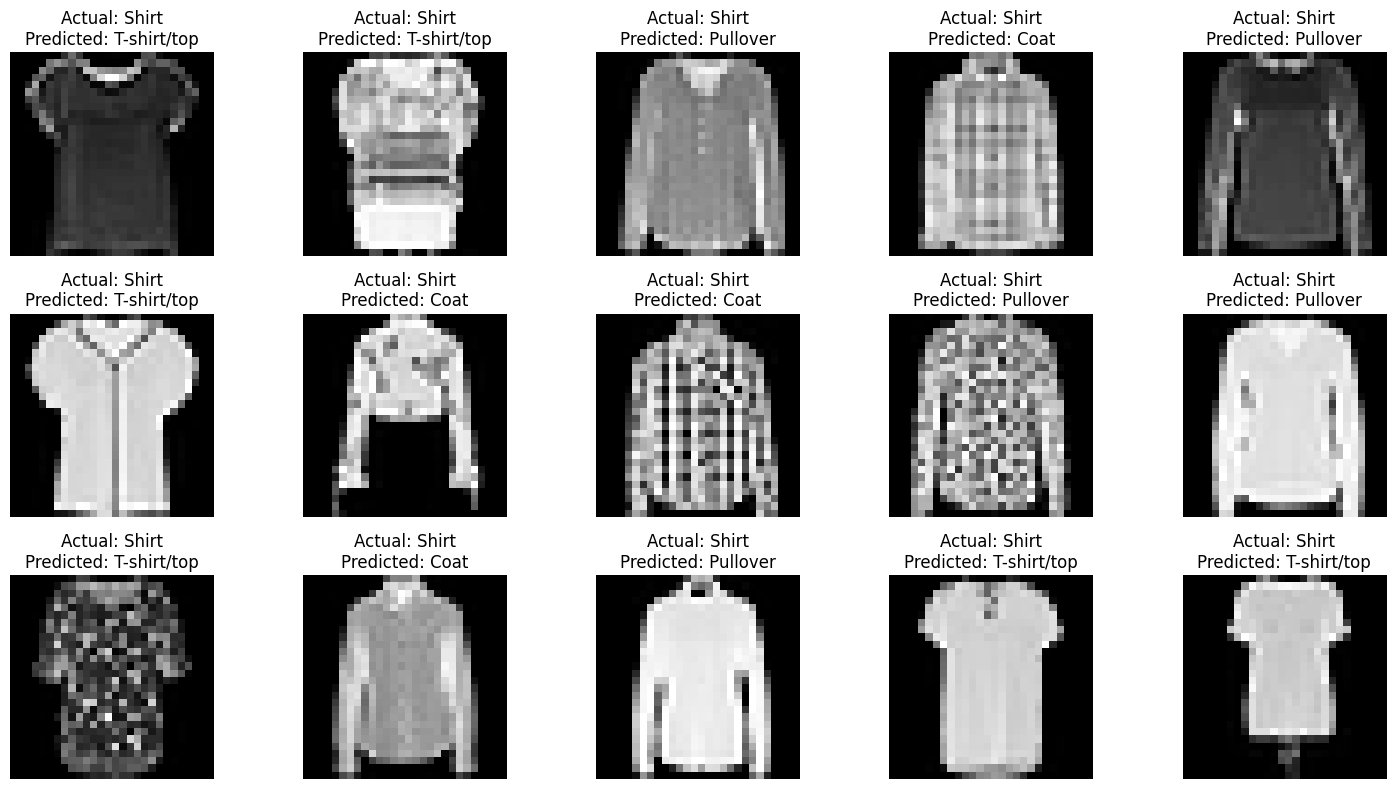

In [63]:
shirt_misclassified = np.where(
    (y_val == shirt_index) & (val_pred != y_val)
)[0]

plt.figure(figsize=(15, 8))

for i in range(15):
    idx = shirt_misclassified[i]

    plt.subplot(3, 5, i + 1)
    plt.imshow(x_val[idx], cmap='gray')

    actual = class_names[y_val[idx]]
    predicted = class_names[val_pred[idx]]

    plt.title(f"Actual: {actual}\nPredicted: {predicted}")
    plt.axis('off')

plt.tight_layout()
plt.show()

In [64]:
X_train_cnn = np.expand_dims(X_train, axis=-1)
X_val_cnn = np.expand_dims(x_val, axis=-1)

print("Training shape:", X_train_cnn.shape)
print("Validation shape:", X_val_cnn.shape)

Training shape: (54000, 28, 28, 1)
Validation shape: (6000, 28, 28, 1)


In [65]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input, Conv2D, MaxPooling2D,
    Flatten, Dense, Dropout
)

cnn_model = Sequential([
    Input(shape=(28, 28, 1)),

    Conv2D(32, (3, 3), activation='relu'),

    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation='relu'),

    MaxPooling2D((2, 2)),

    Flatten(),

    Dense(128, activation='relu'),

    Dropout(0.3),

    Dense(10, activation='softmax')
])

In [66]:
cnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [67]:
cnn_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [68]:
history = cnn_model.fit(
    X_train_cnn,
    Y_train,
    epochs=10,
    batch_size=64,
    validation_data=(X_val_cnn, y_val)
)

Epoch 1/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 8s 8ms/step - accuracy: 0.7971 - loss: 0.5593 - val_accuracy: 0.8543 - val_loss: 0.3968
Epoch 2/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - accuracy: 0.8685 - loss: 0.3654 - val_accuracy: 0.8763 - val_loss: 0.3351
Epoch 3/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.8854 - loss: 0.3149 - val_accuracy: 0.8888 - val_loss: 0.3069
Epoch 4/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.8958 - loss: 0.2839 - val_accuracy: 0.9008 - val_loss: 0.2726
Epoch 5/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.9043 - loss: 0.2593 - val_accuracy: 0.9068 - val_loss: 0.2624
Epoch 6/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.9123 - loss: 0.2391 - val_accuracy: 0.9090 - val_loss: 0.2558
Epoch 7/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.9193 - loss: 0.2210 - val_accuracy: 0.9117 - val_loss: 0.2503
Epoch 8/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.9247 - loss: 0.2046 - val_accuracy: 0.

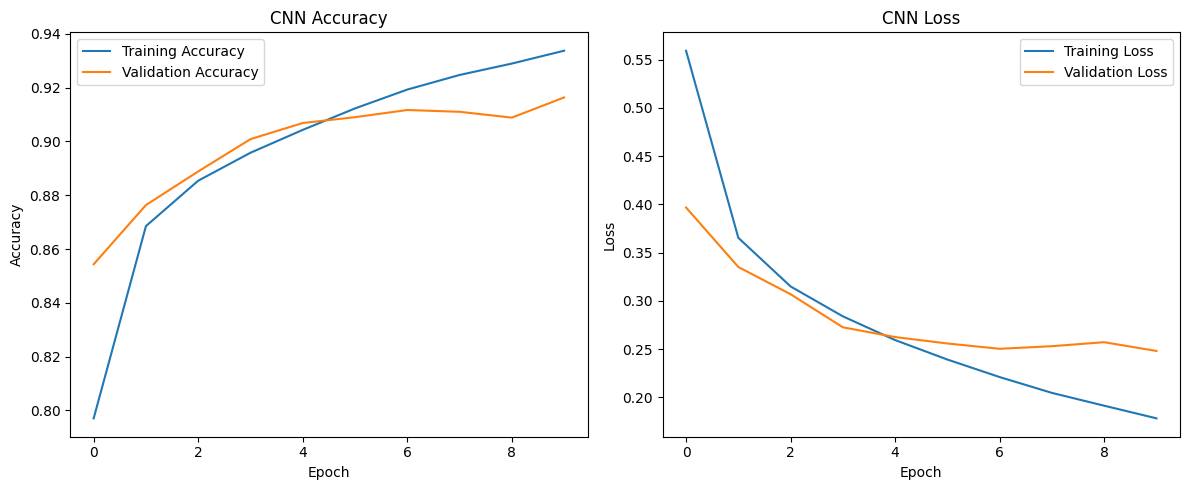

In [69]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

# Accuracy
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('CNN Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# Loss
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('CNN Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

In [70]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

In [72]:
history = cnn_model.fit(
    X_train_cnn,
    Y_train,
    epochs=20,
    batch_size=64,
    validation_data=(X_val_cnn, y_val),
    callbacks=[early_stop]
)

Epoch 1/20
844/844 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - accuracy: 0.9417 - loss: 0.1551 - val_accuracy: 0.9123 - val_loss: 0.2778
Epoch 2/20
844/844 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - accuracy: 0.9441 - loss: 0.1463 - val_accuracy: 0.9135 - val_loss: 0.2679
Epoch 3/20
844/844 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - accuracy: 0.9472 - loss: 0.1391 - val_accuracy: 0.9175 - val_loss: 0.2665
Epoch 4/20
844/844 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - accuracy: 0.9512 - loss: 0.1285 - val_accuracy: 0.9127 - val_loss: 0.2801
Epoch 5/20
844/844 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - accuracy: 0.9525 - loss: 0.1248 - val_accuracy: 0.9115 - val_loss: 0.2846
Epoch 6/20
844/844 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - accuracy: 0.9544 - loss: 0.1173 - val_accuracy: 0.9085 - val_loss: 0.3023


In [103]:
val_loss, val_accuracy = cnn_model.evaluate(
    X_val_cnn,
    y_val
)

print("Validation Loss:", val_loss)
print("Validation Accuracy:", val_accuracy * 100)

188/188 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9175 - loss: 0.2665
Validation Loss: 0.26645272970199585
Validation Accuracy: 91.75000190734863


In [75]:
# Get predictions from CNN
cnn_probabilities = cnn_model.predict(X_val_cnn)

# Convert probabilities into class predictions
cnn_val_pred = np.argmax(cnn_probabilities, axis=1)

print("Predictions:", cnn_val_pred[:10])
print("Actual labels:", y_val[:10])

188/188 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
Predictions: [3 1 9 8 2 1 2 9 3 4]
Actual labels: [3 1 9 8 2 1 2 9 3 4]


<Figure size 1000x800 with 0 Axes>

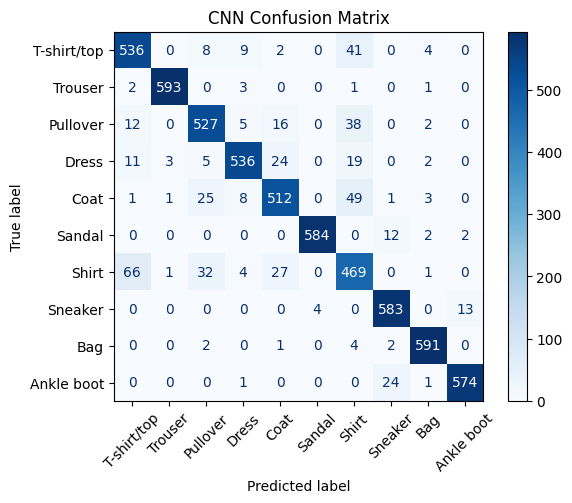

In [77]:
cm = confusion_matrix(y_val, cnn_val_pred)

plt.figure(figsize=(10, 8))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(cmap='Blues', xticks_rotation=45)
plt.title("CNN Confusion Matrix")
plt.show()

In [78]:


cm = confusion_matrix(y_val, cnn_val_pred)

print(cm)

[[536   0   8   9   2   0  41   0   4   0]
 [  2 593   0   3   0   0   1   0   1   0]
 [ 12   0 527   5  16   0  38   0   2   0]
 [ 11   3   5 536  24   0  19   0   2   0]
 [  1   1  25   8 512   0  49   1   3   0]
 [  0   0   0   0   0 584   0  12   2   2]
 [ 66   1  32   4  27   0 469   0   1   0]
 [  0   0   0   0   0   4   0 583   0  13]
 [  0   0   2   0   1   0   4   2 591   0]
 [  0   0   0   1   0   0   0  24   1 574]]


In [79]:
print(classification_report(
    y_val,
    cnn_val_pred,
    target_names=class_names
))

              precision    recall  f1-score   support

 T-shirt/top       0.85      0.89      0.87       600
     Trouser       0.99      0.99      0.99       600
    Pullover       0.88      0.88      0.88       600
       Dress       0.95      0.89      0.92       600
        Coat       0.88      0.85      0.87       600
      Sandal       0.99      0.97      0.98       600
       Shirt       0.76      0.78      0.77       600
     Sneaker       0.94      0.97      0.95       600
         Bag       0.97      0.98      0.98       600
  Ankle boot       0.97      0.96      0.97       600

    accuracy                           0.92      6000
   macro avg       0.92      0.92      0.92      6000
weighted avg       0.92      0.92      0.92      6000



In [102]:
X_test_cnn = np.expand_dims(all_featuresTest, axis=-1)

print(X_test_cnn.shape)
print(labelTest.shape)

(10000, 28, 28, 1)
(10000,)


In [87]:
X_test_cnn = X_test_cnn / 255.0

In [88]:
test_loss, test_accuracy = cnn_model.evaluate(
    X_test_cnn,
    labelTest
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy * 100)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9193 - loss: 0.2479
Test Loss: 0.24793650209903717
Test Accuracy: 91.93000197410583


In [89]:
print("Minimum pixel value:", X_test_cnn.min())
print("Maximum pixel value:", X_test_cnn.max())

print("Training minimum:", X_train_cnn.min())
print("Training maximum:", X_train_cnn.max())

Minimum pixel value: 0.0
Maximum pixel value: 1.0
Training minimum: 0.0
Training maximum: 1.0


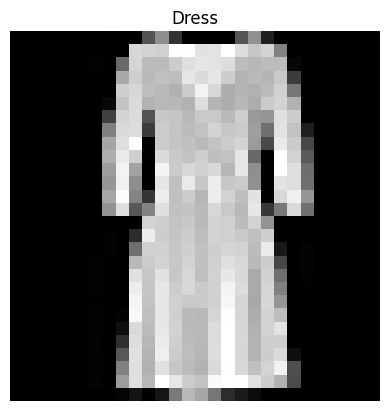

In [90]:
image_index = 10
plt.imshow(X_test_cnn[image_index].squeeze(), cmap='gray')
plt.title(class_names[labelTest[image_index]])
plt.axis('off')
plt.show()

In [91]:
from tensorflow.keras.models import Model

# Get the output of the first convolution layer
first_conv_layer = cnn_model.layers[0]

feature_extractor = Model(
    inputs=cnn_model.inputs,
    outputs=first_conv_layer.output
)

# Pass our selected image through the layer
image = X_test_cnn[image_index:image_index+1]

feature_maps = feature_extractor.predict(image)

print(feature_maps.shape)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
(1, 26, 26, 32)


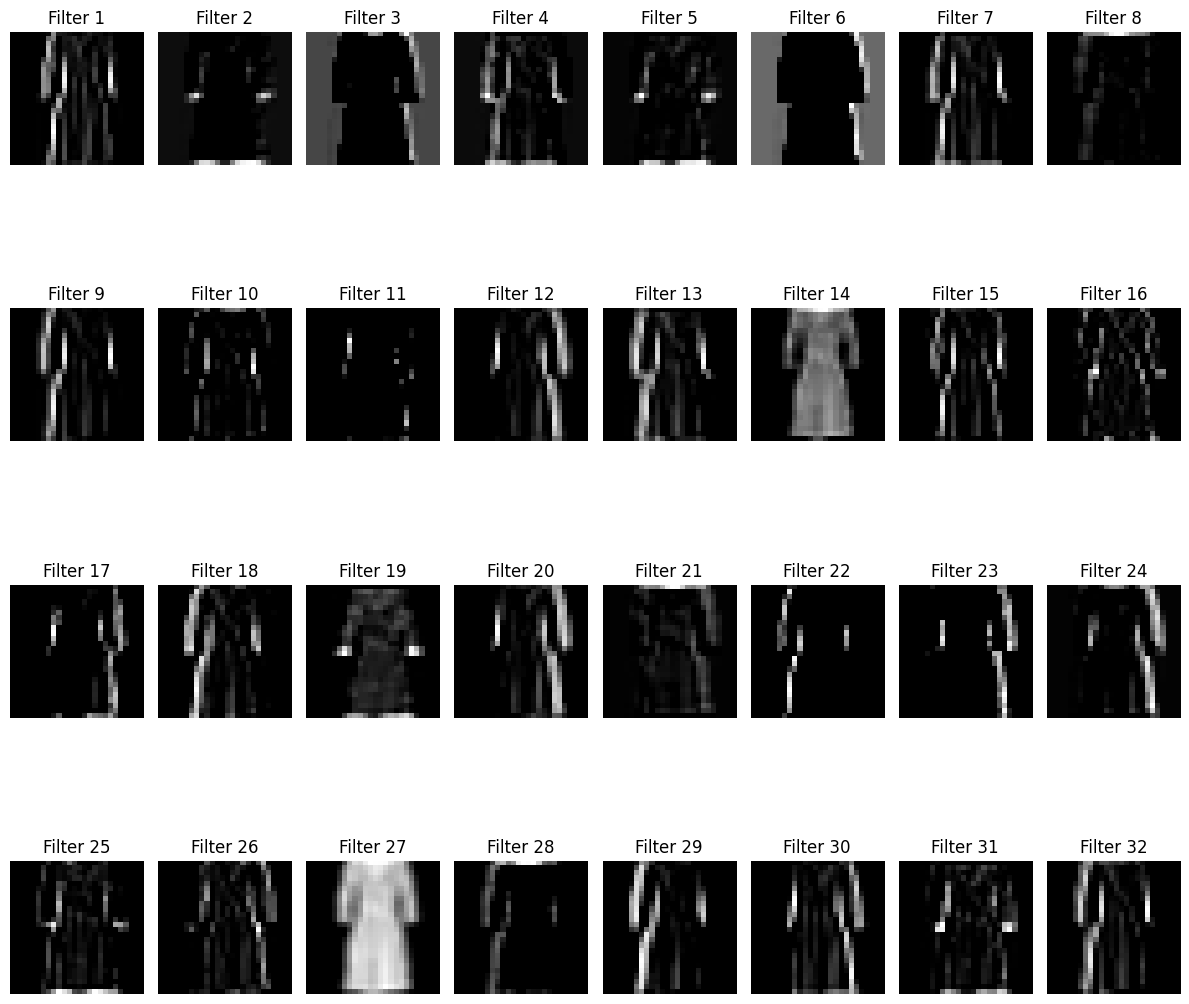

In [92]:
plt.figure(figsize=(12, 12))

for i in range(32):
    plt.subplot(4, 8, i + 1)
    plt.imshow(feature_maps[0, :, :, i], cmap='gray')
    plt.title(f"Filter {i+1}")
    plt.axis('off')

plt.tight_layout()
plt.show()

In [93]:
second_conv_layer = cnn_model.layers[2]

second_feature_extractor = Model(
    inputs=cnn_model.inputs,
    outputs=second_conv_layer.output
)

second_feature_maps = second_feature_extractor.predict(image)

print(second_feature_maps.shape)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step
(1, 11, 11, 64)


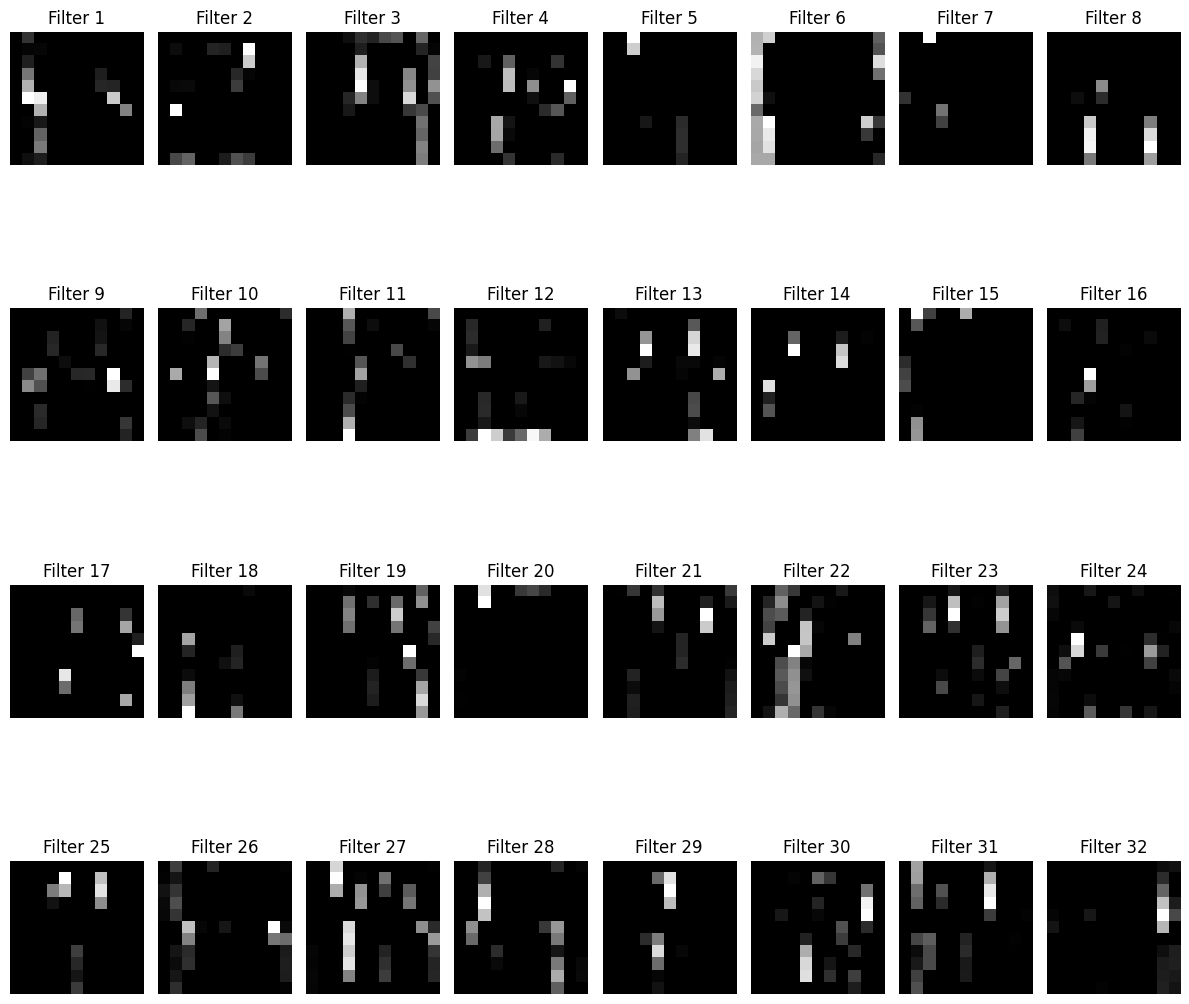

In [94]:
plt.figure(figsize=(12, 12))

for i in range(32):
    plt.subplot(4, 8, i + 1)
    plt.imshow(second_feature_maps[0, :, :, i], cmap='gray')
    plt.title(f"Filter {i+1}")
    plt.axis('off')

plt.tight_layout()
plt.show()

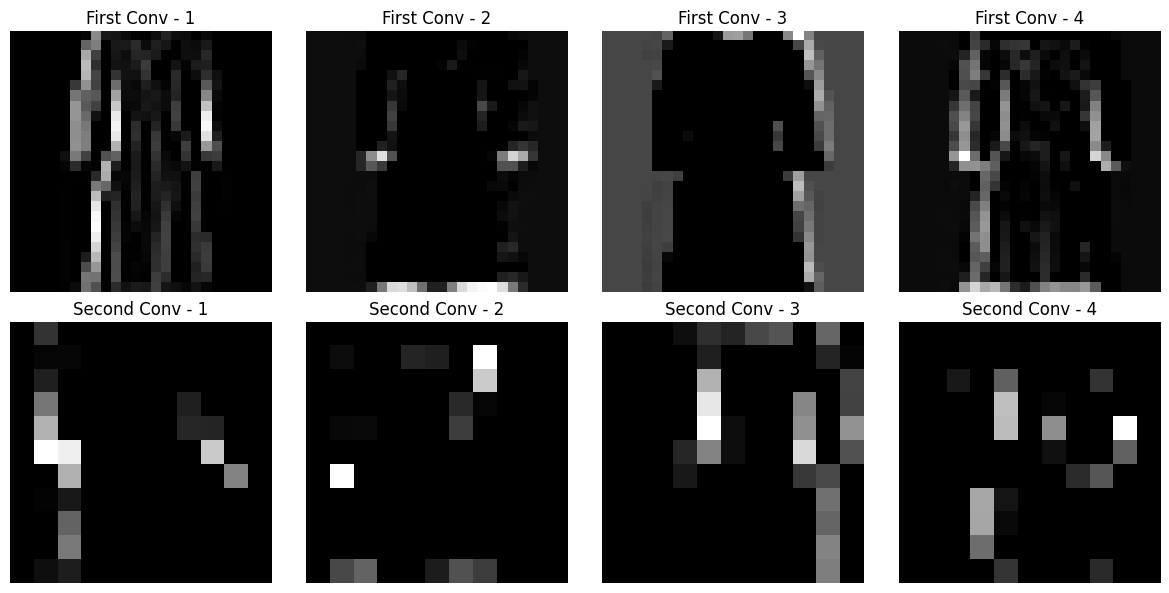

In [95]:
plt.figure(figsize=(12, 6))

for i in range(4):
    # First convolution
    plt.subplot(2, 4, i + 1)
    plt.imshow(feature_maps[0, :, :, i], cmap='gray')
    plt.title(f"First Conv - {i+1}")
    plt.axis('off')

    # Second convolution
    plt.subplot(2, 4, i + 5)
    plt.imshow(second_feature_maps[0, :, :, i], cmap='gray')
    plt.title(f"Second Conv - {i+1}")
    plt.axis('off')

plt.tight_layout()
plt.show()

In [96]:
# Get weights from the first convolution layer
filters, biases = cnn_model.layers[0].get_weights()

print("Filters shape:", filters.shape)
print("Biases shape:", biases.shape)

Filters shape: (3, 3, 1, 32)
Biases shape: (32,)


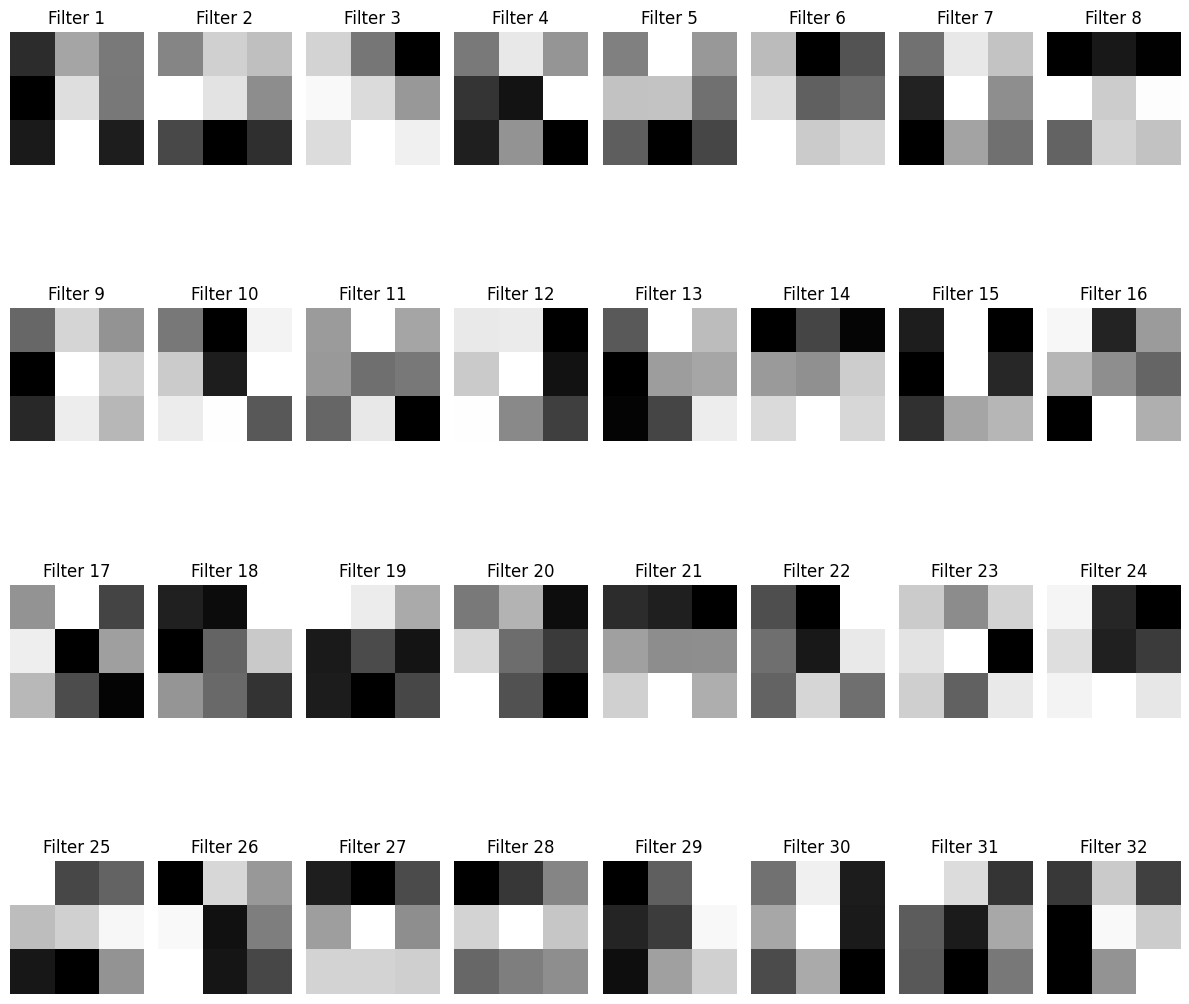

In [97]:
plt.figure(figsize=(12, 12))

for i in range(32):
    plt.subplot(4, 8, i + 1)

    plt.imshow(filters[:, :, 0, i], cmap='gray')
    plt.title(f"Filter {i+1}")
    plt.axis('off')

plt.tight_layout()
plt.show()

In [99]:
cnn_no_pool = Sequential([
    Input(shape=(28, 28, 1)),

    Conv2D(32, (3, 3), activation='relu'),

    Conv2D(64, (3, 3), activation='relu'),

    Flatten(),

    Dense(128, activation='relu'),

    Dropout(0.3),

    Dense(10, activation='softmax')
])

cnn_no_pool.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

history_no_pool = cnn_no_pool.fit(
    X_train_cnn,
    Y_train,
    epochs=20,
    batch_size=64,
    validation_data=(X_val_cnn, y_val),
    callbacks=[early_stop]
)

Epoch 1/20
844/844 ━━━━━━━━━━━━━━━━━━━━ 40s 47ms/step - accuracy: 0.8445 - loss: 0.4377 - val_accuracy: 0.8878 - val_loss: 0.3097
Epoch 2/20
844/844 ━━━━━━━━━━━━━━━━━━━━ 39s 46ms/step - accuracy: 0.8985 - loss: 0.2765 - val_accuracy: 0.9015 - val_loss: 0.2579
Epoch 3/20
844/844 ━━━━━━━━━━━━━━━━━━━━ 39s 46ms/step - accuracy: 0.9191 - loss: 0.2185 - val_accuracy: 0.9060 - val_loss: 0.2517
Epoch 4/20
844/844 ━━━━━━━━━━━━━━━━━━━━ 39s 46ms/step - accuracy: 0.9368 - loss: 0.1713 - val_accuracy: 0.9083 - val_loss: 0.2557
Epoch 5/20
844/844 ━━━━━━━━━━━━━━━━━━━━ 38s 45ms/step - accuracy: 0.9488 - loss: 0.1370 - val_accuracy: 0.9172 - val_loss: 0.2635
Epoch 6/20
844/844 ━━━━━━━━━━━━━━━━━━━━ 39s 46ms/step - accuracy: 0.9605 - loss: 0.1066 - val_accuracy: 0.9163 - val_loss: 0.2689


In [100]:
test_loss, test_accuracy = cnn_no_pool.evaluate(
    X_test_cnn,
    labelTest
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy * 100)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9147 - loss: 0.2391
Test Loss: 0.23911742866039276
Test Accuracy: 91.46999716758728


In [105]:
val_loss, val_accuracy = cnn_no_pool.evaluate(
    X_val_cnn,
    y_val
)

print("Validation Loss:", val_loss)
print("Validation Accuracy:", val_accuracy * 100)

188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9060 - loss: 0.2517
Validation Loss: 0.2517364025115967
Validation Accuracy: 90.6000018119812
